## Algoritmo: Árbol de Decisión (CART) – Clasificación

### Contexto del caso
El dataset proviene de una práctica judicial real: alrededor de 2012, la Universidad de Pensilvania y la Junta de Libertad Condicional de Pensilvania (PBPP) desarrollaron un modelo para estimar el **riesgo de reincidencia** antes de las audiencias de libertad condicional. Es un caso de **justicia predictiva**: el modelo apoya una decisión que afecta la libertad individual y la seguridad pública.

**Variable respuesta `Status`:** 0 = completó la libertad condicional sin violaciones; 1 = violó las condiciones o reincidió.

**¿Qué error es más grave?**
- **Falso negativo:** el modelo dice "no reincidirá" a alguien que sí reincide → riesgo para la seguridad pública.
- **Falso positivo:** el modelo marca como "riesgo" a alguien que habría cumplido → puede negarse la libertad a una persona.

Se **prioriza el Recall** de la clase 1 (detectar a quienes reinciden) y se usa el **F1 como desempate**, para no aumentar innecesariamente los falsos positivos.

**Flujo de trabajo:**
1. Revisión de los datos (duplicados y tipos de variables)
2. Train / Test estratificado (80 / 20)
3. Para **cada estrategia de balance** de clases, búsqueda de hiperparámetros del árbol (pre-poda) con GridSearchCV
4. Elección de la mejor estrategia y **post-poda** con `ccp_alpha`
5. Evaluación final en Test, importancia de variables y reglas del árbol

In [1]:
# ==================================================
# 0. LIBRERÍAS
# ==================================================
# !pip install imbalanced-learn

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import (accuracy_score, recall_score, precision_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report)
from sklearn.base import clone

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler, SMOTE, BorderlineSMOTE, ADASYN
from imblearn.combine import SMOTETomek, SMOTEENN

import warnings
warnings.filterwarnings('ignore')

In [2]:
# ==================================================
# 1. DATOS
# ==================================================
datos = pd.read_csv("Parole.csv", sep = ";")

print("Dimensiones del dataset:", datos.shape)
print("Valores faltantes:", datos.isna().sum().sum())
datos.head()

Dimensiones del dataset: (675, 9)
Valores faltantes: 0


,Genero,Raza,Edad,Estado,Tiempo,Sentencia,Ofensas,Crimen,Status
0,Masculino,Blanca,33,Otro,5.5,18,No,Transito,0
1,Femenino,Blanca,40,Otro,5.4,12,No,Drogas,0
2,Masculino,Negra,30,Otro,5.6,12,No,Drogas,0
3,Masculino,Blanca,22,Otro,5.7,18,No,Otro,0
4,Masculino,Negra,22,Otro,5.4,12,No,Otro,0


### 1.1 Registros repetidos
Se revisan las filas idénticas en todas sus variables.

In [3]:
repetidos = datos.duplicated(keep = False)
print("Filas que se repiten (incluyendo la primera aparición):", repetidos.sum())
print("Status de esas filas:", datos.loc[repetidos, "Status"].value_counts().to_dict())

Filas que se repiten (incluyendo la primera aparición): 48
Status de esas filas: {0: 48}


**Decisión: se conservan.** El dataset **no tiene un identificador** de cada persona, y las variables tienen pocos valores posibles (2 géneros, 2 razas, 4 estados, 4 tipos de crimen, sentencias en meses enteros…). Es perfectamente posible que **dos personas distintas** tengan el mismo perfil. Eliminarlas significaría quitar casos reales, y como todas son de la clase 0, además alteraría artificialmente la proporción de clases.

In [4]:
# Variables predictoras y respuesta
X = datos.drop(columns = "Status")
y = datos["Status"].astype(int)
class_names = ["0: sin violación", "1: violación"]

variables_categoricas = X.select_dtypes(include = "object").columns.tolist()
variables_numericas   = X.select_dtypes(include = "number").columns.tolist()

print("Variables categóricas:", variables_categoricas)
print("Variables numéricas:  ", variables_numericas)

print("\nDistribución de clases:")
print(pd.DataFrame({"n": y.value_counts(), "%": (y.value_counts(normalize = True) * 100).round(1)}))

Variables categóricas: ['Genero', 'Raza', 'Estado', 'Ofensas', 'Crimen']
Variables numéricas:   ['Edad', 'Tiempo', 'Sentencia']

Distribución de clases:
          n     %
Status           
0       597  88.4
1        78  11.6


**Observaciones:**
- Las clases están **muy desbalanceadas** (≈88 % / 12 %): un modelo que siempre prediga "0" tendría ≈88 % de accuracy y no detectaría ninguna reincidencia.
- **No hay valores faltantes**, así que no se necesita imputación.
- **Outliers:** no se aplica detección. Los árboles de decisión son **robustos a valores extremos**: dividen los datos con umbrales (por ejemplo, `Tiempo ≤ 2.5`) y no con distancias ni promedios, así que un valor extremo no distorsiona las divisiones. Además, 5 de las 8 variables son categóricas.

In [5]:
# ==================================================
# 2. TRAIN / TEST  (¡ANTES de cualquier preprocesamiento!)
# ==================================================
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size = 0.20,
    stratify = y,
    random_state = 42
)

print("Train:", X_train.shape, " | Test:", X_test.shape)
print("Casos de clase 1 -> Train: {} | Test: {}".format(y_train.sum(), y_test.sum()))

Train: (540, 8)  | Test: (135, 8)
Casos de clase 1 -> Train: 62 | Test: 16


## 3. Balance de clases + pre-poda: una búsqueda completa por estrategia
Para comparar las estrategias de balance de forma justa, **cada una se evalúa con su propio árbol optimizado**: para cada estrategia se ejecuta un GridSearchCV completo y se guarda su mejor combinación.

### Pipeline
`One-Hot Encoding → Estrategia de balance → Árbol`

`DecisionTreeClassifier` solo acepta variables numéricas, por eso las 5 variables categóricas se transforman con **One-Hot Encoding** (una columna 0/1 por categoría), **dentro del pipeline** para evitar data leakage. El balanceo también va dentro del pipeline y solo se aplica al entrenar.

### Estrategias de balance (vistas en clase)
| Estrategia | Idea |
|---|---|
| **Base** | sin balanceo |
| **Pesos de clase** | cada error en la clase minoritaria pesa más al construir el árbol |
| **Random Undersampling** | elimina al azar casos de la clase mayoritaria |
| **Random Oversampling** | duplica al azar casos de la clase minoritaria |
| **SMOTE** | crea casos sintéticos interpolando entre vecinos de la clase minoritaria |
| **Borderline-SMOTE** | genera casos sintéticos solo cerca de la frontera entre clases |
| **ADASYN** | genera más casos donde la clase minoritaria es más difícil de aprender |
| **SMOTE + Tomek** | SMOTE y luego elimina pares de puntos de clases distintas muy cercanos |
| **SMOTE + ENN** | SMOTE y luego elimina observaciones mal clasificadas por sus vecinos |

### Hiperparámetros del árbol (tabla de la clase)
| Hiperparámetro | Valores | Qué controla |
|---|---|---|
| `criterion` | gini, entropy | medida de impureza para elegir cada división |
| `max_depth` | 2, 3, 4, 5, 6, 8, 10, None | profundidad máxima del árbol |
| `min_samples_split` | 2, 5, 10, 20 | mínimo de observaciones para dividir un nodo |
| `min_samples_leaf` | 1, 2, 5, 10 | mínimo de observaciones en una hoja |
| `max_features` | None, sqrt | número de variables consideradas en cada división (con 17 columnas, `log2` y `sqrt` dan el mismo valor, 4, así que basta con `sqrt`) |

### Criterio de selección
**Máximo Recall** en validación cruzada (5 folds estratificados); entre las combinaciones empatadas (Recall a menos de 0.005 del máximo), la de **mayor F1**.

In [6]:
def preprocesador():
    return ColumnTransformer([
        ("num", "passthrough", variables_numericas),
        ("cat", OneHotEncoder(handle_unknown = "ignore"), variables_categoricas)
    ])

param_grid = {
    "tree__criterion":         ["gini", "entropy"],
    "tree__max_depth":         [2, 3, 4, 5, 6, 8, 10, None],
    "tree__min_samples_split": [2, 5, 10, 20],
    "tree__min_samples_leaf":  [1, 2, 5, 10],
    "tree__max_features":      [None, "sqrt"]
}

validacion = StratifiedKFold(n_splits = 5, shuffle = True, random_state = 42)

scoring = {
    "Recall": "recall",
    "F1": "f1",
    "ROC_AUC": "roc_auc"
}

# Máximo Recall; si hay empate (diferencia < 0.005), se desempata con el mayor F1
TOLERANCIA = 0.005

def recall_con_desempate_f1(cv_results):
    recall = np.asarray(cv_results["mean_test_Recall"])
    f1 = np.asarray(cv_results["mean_test_F1"])
    candidatos = np.where(recall >= recall.max() - TOLERANCIA)[0]
    return candidatos[np.argmax(f1[candidatos])]

estrategias = {
    "Base (sin balanceo)":  (None, None),
    "Pesos de clase":       (None, "balanced"),
    "Random Undersampling": (RandomUnderSampler(random_state = 42), None),
    "Random Oversampling":  (RandomOverSampler(random_state = 42), None),
    "SMOTE":                (SMOTE(random_state = 42), None),
    "Borderline-SMOTE":     (BorderlineSMOTE(random_state = 42), None),
    "ADASYN":               (ADASYN(random_state = 42), None),
    "SMOTE + Tomek":        (SMOTETomek(random_state = 42), None),
    "SMOTE + ENN":          (SMOTEENN(random_state = 42), None)
}

In [7]:
grids = {}
filas = []

for nombre, (metodo, pesos) in estrategias.items():
    pasos = [("preprocesamiento", preprocesador())]
    if metodo is not None:
        pasos.append(("balance", metodo))
    pasos.append(("tree", DecisionTreeClassifier(class_weight = pesos, random_state = 42)))

    grid = GridSearchCV(
        ImbPipeline(pasos),
        param_grid,
        cv = validacion,
        scoring = scoring,
        refit = recall_con_desempate_f1,
        n_jobs = -1
    ).fit(X_train, y_train)
    grids[nombre] = grid

    i, r = grid.best_index_, grid.cv_results_
    bp = grid.best_params_
    filas.append({
        "Estrategia": nombre,
        "criterion": bp["tree__criterion"],
        "max_depth": bp["tree__max_depth"],
        "min_split": bp["tree__min_samples_split"],
        "min_leaf": bp["tree__min_samples_leaf"],
        "max_features": str(bp["tree__max_features"]),
        "Recall CV": round(r["mean_test_Recall"][i], 4),
        "Recall sd": round(r["std_test_Recall"][i], 4),
        "F1 CV": round(r["mean_test_F1"][i], 4),
        "AUC CV": round(r["mean_test_ROC_AUC"][i], 4)
    })

tabla_estrategias = pd.DataFrame(filas).set_index("Estrategia")
tabla_estrategias

,criterion,max_depth,min_split,min_leaf,max_features,Recall CV,Recall sd,F1 CV,AUC CV
Estrategia,,,,,,,,,
Base (sin balanceo),gini,10,10,2,sqrt,0.3885,0.1457,0.4354,0.6960
Pesos de clase,entropy,3,2,1,None,0.8269,0.1560,0.3572,0.8191
Random Undersampling,entropy,5,2,2,None,0.8115,0.1597,0.3864,0.7785
Random Oversampling,gini,3,2,1,None,0.8397,0.0881,0.3473,0.8200
SMOTE,entropy,3,2,1,None,0.6346,0.2211,0.4357,0.8146
Borderline-SMOTE,entropy,3,2,1,None,0.6167,0.1445,0.4605,0.8359
ADASYN,entropy,3,2,1,None,0.7141,0.1587,0.4645,0.8280
SMOTE + Tomek,entropy,3,2,1,None,0.6346,0.2211,0.4357,0.8122
SMOTE + ENN,entropy,4,10,2,sqrt,0.7603,0.1275,0.3483,0.7774


In [8]:
# Mejor estrategia: mismo criterio (máximo Recall, desempate por F1)
candidatos = tabla_estrategias[tabla_estrategias["Recall CV"] >= tabla_estrategias["Recall CV"].max() - TOLERANCIA]
mejor_estrategia = candidatos["F1 CV"].idxmax()

best_prepoda  = grids[mejor_estrategia].best_estimator_
arbol_prepoda = best_prepoda.named_steps["tree"]

print("Mejor estrategia de balance:", mejor_estrategia)
print(f"Estructura del árbol: Nodos = {arbol_prepoda.tree_.node_count} | "
      f"Hojas = {arbol_prepoda.get_n_leaves()} | Prof. = {arbol_prepoda.get_depth()}")

Mejor estrategia de balance: Random Oversampling
Estructura del árbol: Nodos = 15 | Hojas = 8 | Prof. = 3


**Decisión: Random Oversampling.**
- Obtiene el **mayor Recall** en validación cruzada (0.840) y además la **menor desviación** entre folds (0.088): es la estrategia más **estable**.
- **Pesos de clase** queda muy cerca (Recall 0.827). Tiene sentido: duplicar casos de la clase minoritaria y darles más peso son ideas casi equivalentes para un árbol.
- **Random Undersampling** baja un poco: elimina al azar la mayoría de los casos de clase 0, y con tan pocos datos el árbol se vuelve más inestable.
- **SMOTE y sus variantes** logran menos Recall. Con variables One-Hot crean casos sintéticos con categorías "intermedias" (por ejemplo, `Raza_Negra = 0.4`) que no existen en la realidad.
- Sin balanceo, el árbol solo detecta ≈39 % de las reincidencias.

## 4. Post-poda (`ccp_alpha`)
Se calcula la secuencia de valores de α a partir del árbol ganador, con los mismos datos con los que se entrenó (codificados y balanceados), y se elige α con validación cruzada y el mismo criterio.

In [9]:
# 1. Aplicando preprocesamiento (y balanceo, si corresponde) en la data de entrenamiento
X_train_proc = best_prepoda.named_steps["preprocesamiento"].transform(X_train)
if "balance" in best_prepoda.named_steps:
    X_train_proc, y_train_proc = best_prepoda.named_steps["balance"].fit_resample(X_train_proc, y_train)
else:
    y_train_proc = y_train

# 2. Path de poda sobre el árbol ganador
path       = arbol_prepoda.cost_complexity_pruning_path(X_train_proc, y_train_proc)
ccp_alphas = np.unique(path.ccp_alphas[:-1])
print(f"Valores de ccp_alpha a evaluar: {len(ccp_alphas)}")

# 3. Buscar el mejor ccp_alpha con CV
grid_post = GridSearchCV(
    clone(best_prepoda),
    param_grid = {"tree__ccp_alpha": ccp_alphas},
    cv = validacion,
    scoring = scoring,
    refit = recall_con_desempate_f1,
    n_jobs = -1
).fit(X_train, y_train)

mejor_alpha = grid_post.best_params_["tree__ccp_alpha"]
print(f"Mejor ccp_alpha: {mejor_alpha:.6f}")

Valores de ccp_alpha a evaluar: 7


Mejor ccp_alpha: 0.000000


In [10]:
# Modelo final
if mejor_alpha > 0:
    modelo_final, tipo = grid_post.best_estimator_, "post-podado"
    r, i = grid_post.cv_results_, grid_post.best_index_
else:
    modelo_final, tipo = best_prepoda, "pre-podado (la post-poda eligió α = 0)"
    r, i = grids[mejor_estrategia].cv_results_, grids[mejor_estrategia].best_index_

arbol_final = modelo_final.named_steps["tree"]
p = arbol_final.get_params()

mejor = pd.DataFrame({
    "Balance": [mejor_estrategia],
    "criterion": [p["criterion"]],
    "max_depth": [p["max_depth"]],
    "min_split": [p["min_samples_split"]],
    "min_leaf": [p["min_samples_leaf"]],
    "max_features": [str(p["max_features"])],
    "ccp_alpha": [round(p["ccp_alpha"], 6)],
    "Hojas": [arbol_final.get_n_leaves()],
    "Recall CV": [round(r["mean_test_Recall"][i], 4)],
    "F1 CV": [round(r["mean_test_F1"][i], 4)],
    "AUC CV": [round(r["mean_test_ROC_AUC"][i], 4)]
}, index = ["Mejor modelo"])

print("Árbol final:", tipo)
mejor

Árbol final: pre-podado (la post-poda eligió α = 0)


,Balance,criterion,max_depth,min_split,min_leaf,max_features,ccp_alpha,Hojas,Recall CV,F1 CV,AUC CV
Mejor modelo,Random Oversampling,gini,3,2,1,None,0.0,8,0.8397,0.3473,0.82


**Mejor modelo: Random Oversampling + árbol CART (Gini) de profundidad 3, con 8 hojas.**
- En validación cruzada detecta en promedio al **≈84 % de quienes reinciden** (Recall CV = 0.840), con un AUC de 0.82.
- Es un árbol **pequeño e interpretable**: la pre-poda (profundidad máxima 3) ya controla el sobreajuste, y la **post-poda eligió α = 0** (podar más ramas reduciría el Recall).
- **Costo de priorizar el Recall:** el F1 es bajo (0.35) porque la Precision es baja: el modelo marca como "riesgo" a muchas personas que sí cumplen.

In [11]:
# ==================================================
# 5. EVALUACIÓN EN TEST (una sola vez)
# ==================================================
y_pred = modelo_final.predict(X_test)
y_prob = modelo_final.predict_proba(X_test)[:, 1]

metricas_test = pd.DataFrame({
    "Valor": [
        recall_score(y_test, y_pred),
        precision_score(y_test, y_pred),
        f1_score(y_test, y_pred),
        accuracy_score(y_test, y_pred),
        roc_auc_score(y_test, y_prob)
    ]
}, index = ["Recall", "Precision", "F1-Score", "Accuracy", "AUC-ROC"]).round(4)

print("Métricas en Test (clase positiva = violación / reincidencia):")
print(metricas_test)

print("\nReporte de clasificación:")
print(classification_report(y_test, y_pred, target_names = class_names))

Métricas en Test (clase positiva = violación / reincidencia):
            Valor
Recall     0.8125
Precision  0.2063
F1-Score   0.3291
Accuracy   0.6074
AUC-ROC    0.7623

Reporte de clasificación:
                  precision    recall  f1-score   support

0: sin violación       0.96      0.58      0.72       119
    1: violación       0.21      0.81      0.33        16

        accuracy                           0.61       135
       macro avg       0.58      0.70      0.53       135
    weighted avg       0.87      0.61      0.68       135



In [12]:
# Matriz de confusión completa
cm = confusion_matrix(y_test, y_pred)
TN, FP, FN, TP = cm.ravel()

print(pd.DataFrame(cm, index = ["Real 0", "Real 1"], columns = ["Pred 0", "Pred 1"]))
print("\nVerdaderos Negativos (TN):", TN)
print("Falsos Positivos   (FP):", FP, " -> habrían cumplido, pero el modelo los marca como riesgo")
print("Falsos Negativos   (FN):", FN, " -> reincidieron y el modelo NO los detectó")
print("Verdaderos Positivos (TP):", TP)

        Pred 0  Pred 1
Real 0      69      50
Real 1       3      13

Verdaderos Negativos (TN): 69
Falsos Positivos   (FP): 50  -> habrían cumplido, pero el modelo los marca como riesgo
Falsos Negativos   (FN): 3  -> reincidieron y el modelo NO los detectó
Verdaderos Positivos (TP): 13


**Interpretación del Test:**
- El **Recall en Test (0.81)** es muy parecido al de la validación cruzada (0.84): el modelo **generaliza bien**. Detecta a **13 de las 16** personas que reincidieron.
- El costo son **50 falsos positivos**: 42 % de quienes sí cumplieron serían marcados como "riesgo" (Precision = 0.21, es decir, solo 1 de cada 5 personas marcadas reincide realmente).
- **En el contexto del caso**, esto es importante: si el modelo se usara para **negar** la libertad condicional, afectaría a muchas personas que la habrían cumplido. Un uso más responsable sería como **alerta para priorizar supervisión o seguimiento**, no como criterio automático de decisión.

In [13]:
# ==================================================
# 6. IMPORTANCIA DE VARIABLES
# ==================================================
feature_names = modelo_final.named_steps["preprocesamiento"].get_feature_names_out()
feature_names = [f.split("__")[1] for f in feature_names]

df_importancias = (
    pd.DataFrame({
        "Variable":    feature_names,
        "Importancia": arbol_final.feature_importances_
    })
    .sort_values("Importancia", ascending = False)
    .reset_index(drop = True)
)

# Solo variables que el árbol realmente usó
df_imp_activas = df_importancias[df_importancias["Importancia"] > 0].copy()
df_imp_activas["Acumulado"] = df_imp_activas["Importancia"].cumsum()

print(f"Variables usadas: {len(df_imp_activas)} de {len(feature_names)}")
print(df_imp_activas.round(4).to_string(index = False))

Variables usadas: 7 de 17
       Variable  Importancia  Acumulado
Estado_Virginia       0.5977     0.5977
     Ofensas_No       0.2291     0.8268
Crimen_Transito       0.0620     0.8888
      Sentencia       0.0334     0.9222
         Tiempo       0.0331     0.9552
    Raza_Blanca       0.0231     0.9784
           Edad       0.0216     1.0000


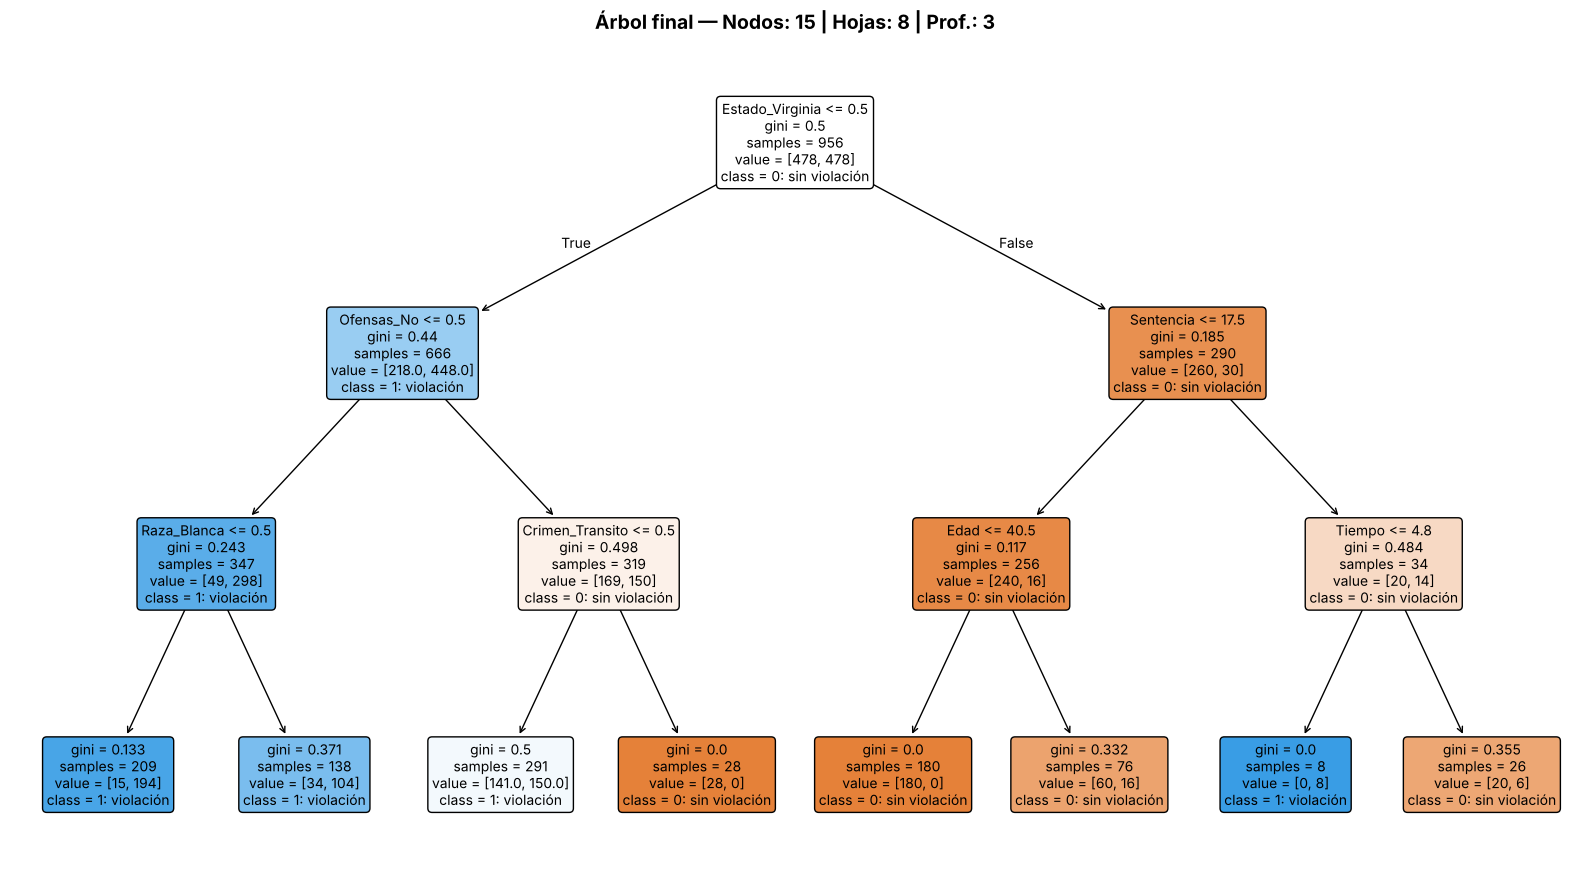

In [14]:
# ==================================================
# 7. ÁRBOL FINAL
# ==================================================
plt.figure(figsize = (max(16, arbol_final.get_n_leaves() * 2), max(8, arbol_final.get_depth() * 3)))
plot_tree(arbol_final,
          feature_names = feature_names,
          class_names = class_names,
          filled = True, rounded = True,
          fontsize = 10)
plt.title(f"Árbol final — Nodos: {arbol_final.tree_.node_count} | "
          f"Hojas: {arbol_final.get_n_leaves()} | Prof.: {arbol_final.get_depth()}",
          fontsize = 14, fontweight = "bold")
plt.tight_layout()
plt.show()

In [15]:
# Reglas del árbol en texto
print(export_text(arbol_final, feature_names = feature_names))

|--- Estado_Virginia <= 0.50
|   |--- Ofensas_No <= 0.50
|   |   |--- Raza_Blanca <= 0.50
|   |   |   |--- class: 1
|   |   |--- Raza_Blanca >  0.50
|   |   |   |--- class: 1
|   |--- Ofensas_No >  0.50
|   |   |--- Crimen_Transito <= 0.50
|   |   |   |--- class: 1
|   |   |--- Crimen_Transito >  0.50
|   |   |   |--- class: 0
|--- Estado_Virginia >  0.50
|   |--- Sentencia <= 17.50
|   |   |--- Edad <= 40.50
|   |   |   |--- class: 0
|   |   |--- Edad >  40.50
|   |   |   |--- class: 0
|   |--- Sentencia >  17.50
|   |   |--- Tiempo <= 4.80
|   |   |   |--- class: 1
|   |   |--- Tiempo >  4.80
|   |   |   |--- class: 0



**Interpretación de las reglas:**
- **`Estado` es la variable más importante** (≈60 % de la importancia).
- **Fuera de Virginia:** se predice **reincidencia** en casi todos los casos; la única excepción son las personas **sin múltiples delitos** cuyo crimen principal es de **tránsito**.
- **En Virginia:** se predice **no reincidencia**, salvo si la **sentencia es mayor a 17.5 meses** y el **tiempo cumplido es de 4.8 años o menos**.
- `Raza` aparece en una división, pero **sus dos ramas predicen la misma clase** (1): no cambia ninguna predicción. Lo mismo pasa con `Edad` en Virginia (ambas ramas predicen 0). El árbol hace esas divisiones porque reducen la impureza (Gini), aunque no cambien la clase final.

## 8. Conclusiones
- **Datos:** las filas repetidas se conservaron, porque sin un identificador pueden ser personas distintas con el mismo perfil. No hay valores faltantes y, al ser un árbol, no se requiere tratar outliers.
- **Balance + pre-poda:** se ejecutó un GridSearchCV completo para cada una de las 9 estrategias de balance; **Random Oversampling** obtuvo el mayor Recall y fue la más estable.
- **Árbol final:** CART (Gini) de profundidad 3, elegido priorizando el **Recall** y desempatando por F1; la post-poda no mejoró el resultado.
- **Test:** Recall de 0.81 (13 de 16 reincidencias detectadas), coherente con la validación cruzada, a costa de muchos falsos positivos.
- **Sin data leakage:** One-Hot y balanceo viven dentro del pipeline; el Test se usó una sola vez.

**Consideraciones éticas (justicia predictiva):** el modelo detecta **asociaciones**, no causas. `Estado` domina las predicciones, lo que refleja diferencias entre jurisdicciones más que características de la persona. `Raza` y `Genero` son atributos sensibles; en el árbol final `Raza` no cambia ninguna predicción. Con una Precision de 0.21, el modelo **no debe usarse como única base** para negar la libertad condicional.